# Leaf Only SAM — zero-shot leaf segmentation on one potato image (Colab reproduction)

**Paper:** *Leaf only SAM: A segment anything pipeline for zero-shot automated leaf segmentation*,
Smart Agricultural Technology (2024), DOI [10.1016/j.atech.2024.100515](https://doi.org/10.1016/j.atech.2024.100515);
preprint [arXiv:2305.09418](https://arxiv.org/abs/2305.09418).
**Author code:** [Dom3442/leafonlysam](https://github.com/Dom3442/leafonlysam) @ commit `6abcf73` (GPL-3.0).
**Sample data:** Zenodo record [7938231](https://zenodo.org/records/7938231) "Potato Leaf data set" (CC-BY).

**Scope (this notebook):** run the authors' released zero-shot pipeline on **one** potato image
(`IMG_8089.JPG`): SAM ViT-H automatic mask generation, then the authors' leaf-only filters
(colour, full-plant removal, shape, too-big removal), and compare detected masks with the record's
reference `.json` leaf annotation.
**Not reproduced:** Mask R-CNN fine-tuning and the paper's recall/precision benchmarks
(that code was never released, and the published full text is paywalled).

**実行環境:** GPU ランタイム（T4）を選択してください（Runtime → Change runtime type → T4 GPU）。
SAM ViT-H 推論は CPU では非常に遅く、著者コードも CUDA 前提です。このノートブックは CUDA がない場合に明示的に停止します。
想定所要時間: 約5〜10分、ダウンロード約2.4 GB（主に SAM ViT-H チェックポイント 2.39 GB）。

*All pipeline logic is copied verbatim from the authors' notebook (GPL-3.0, credited above);
download/validation/visualization glue cells are AI-generated for Colab and labeled as such.*

## 1. Environment check

Verify Python, PyTorch, CUDA and GPU name. The authors' notebook requires `device="cuda"`;
if no GPU is allocated this reproduction stops here.

**日本語:** Python と PyTorch、CUDA の利用可否を確認します。GPU が割り当てられていない場合は、
後段のセルが明確なエラーで停止します（CPU への黙っての代替は行いません）。

In [ ]:
import sys, platform
print("python:", sys.version.split()[0], "| platform:", platform.platform())
import torch
print("torch:", torch.__version__, "| cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))
import cv2, numpy, matplotlib, pandas
print("cv2:", cv2.__version__, "| numpy:", numpy.__version__, "| pandas:", pandas.__version__)

python: 3.13.16 | platform: Linux-6.6.122+-x86_64-with-glibc2.39


torch: 2.11.0+cu130 | cuda available: True
gpu: Tesla T4


cv2: 4.14.0 | numpy: 2.1.3 | pandas: 2.2.3


## 2. Install `segment_anything` (pinned)

Install Meta's `segment-anything` exactly at the commit verified for this reproduction
(`facebookresearch/segment-anything@dca509fe`, repository HEAD as of 2026-10). Everything else the
authors' notebook imports (`numpy`, `cv2`, `matplotlib`, `pandas`) ships with Colab.

**日本語:** 著者が利用した Meta の `segment-anything` を、検証済みコミットに固定してインストールします。

In [ ]:
import subprocess
r = subprocess.run(
    [sys.executable, "-m", "pip", "install", "--quiet",
     "git+https://github.com/facebookresearch/segment-anything.git@dca509fe793f601edb92606367a655c15ac00fdf"],
    check=True)
import segment_anything
print("segment_anything installed from:", segment_anything.__file__)

segment_anything installed from: /usr/local/lib/python3.13/dist-packages/segment_anything/__init__.py


## 3. Download the SAM ViT-H checkpoint (2.39 GB, Colab only)

Fetch the official ViT-H checkpoint (`sam_vit_h_4b8939.pth`) from Meta's public server, the same
file the authors' notebook expects. Validation is by actually loading it with `torch.load` in the
next section (an incomplete download fails loudly there), plus a plausible size guard here.

**日本語:** SAM ViT-H チェックポイント（約2.39 GB）を Meta の公開サーバーから Colab 内にダウンロードします。
サイズの目安を確認し、完全性は次章の `torch.load` で検証します。

In [ ]:
import os, urllib.request, time

CKPT = "sam_vit_h_4b8939.pth"
CKPT_URL = "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth"

if not os.path.exists(CKPT):
    t0 = time.time()
    urllib.request.urlretrieve(CKPT_URL, CKPT)  # bounded by Colab VM network; no auth needed
    print(f"downloaded in {time.time()-t0:.1f}s")
size = os.path.getsize(CKPT)
print(f"checkpoint size: {size/1e9:.2f} GB")
assert size > 2.0e9, "checkpoint looks truncated; rerun this cell" 

downloaded in 13.8s
checkpoint size: 2.56 GB


## 4. Download one annotated sample image from the Zenodo record

Select a deterministic, license-checked sample from the paper's own dataset:
`IMG_8089.JPG` and its reference leaf annotation `IMG_8089.json` (CC-BY), downloaded through the
record's documented API content links and verified against the MD5 checksums returned by the
Zenodo record API (record 7938231, inspected 2026-10-26).

**日本語:** 論文の Zenodo データセット（CC-BY）から、参照アノテーション付きの1枚
`IMG_8089.JPG` とその `.json` を取得し、レコード API が返した MD5 で検証します。

In [ ]:
import hashlib, urllib.request

ZENODO = "https://zenodo.org/api/records/7938231/files/{key}/content"
EXPECTED_MD5 = {"IMG_8089.JPG": "dbf1772e7b52d9da8cf5a48c98d9e84b",
                "IMG_8089.json": "0ac4c35c8d281688eedbe87d5b37bdef"}

os.makedirs("sample", exist_ok=True)
for key, md5 in EXPECTED_MD5.items():
    dest = os.path.join("sample", key)
    if not os.path.exists(dest):
        urllib.request.urlretrieve(ZENODO.format(key=key), dest)
    h = hashlib.md5(open(dest, "rb").read()).hexdigest()
    print(f"{key}: {os.path.getsize(dest):,} bytes | md5 {h} | {'OK' if h == md5 else 'MISMATCH'}")
    assert h == md5, f"checksum mismatch for {key}" 

IMG_8089.JPG: 4,209,872 bytes | md5 dbf1772e7b52d9da8cf5a48c98d9e84b | OK


IMG_8089.json: 2,089,562 bytes | md5 0ac4c35c8d281688eedbe87d5b37bdef | OK


## 5. Inspect the sample and its reference annotation schema

The annotation file's exact schema is not documented in the repository, so we introspect it here
before drawing anything (no hard-coded assumptions). We also confirm the image dimensions and the
0.5× downsize the authors apply.

**日本語:** まず入力画像と参照アノテーション `.json` の内部構造を確認します（スキーマは前提を置かず実データから確認）。

In [ ]:
import json, cv2

image_bgr = cv2.imread("sample/IMG_8089.JPG")
print("image (BGR):", image_bgr.shape, "-> after authors' 0.5x resize:",
      (image_bgr.shape[0]//2, image_bgr.shape[1]//2, 3))

ann = json.load(open("sample/IMG_8089.json"))

def describe(obj, depth=0, name="root"):
    pad = "  " * depth
    if isinstance(obj, dict):
        print(f"{pad}{name}: dict with keys {list(obj.keys())[:12]}")
        if depth < 2:
            for k, v in list(obj.items())[:12]:
                describe(v, depth + 1, k)
    elif isinstance(obj, list):
        print(f"{pad}{name}: list, len={len(obj)}, first type={type(obj[0]).__name__ if obj else 'empty'}")
        if depth < 2 and obj:
            describe(obj[0], depth + 1, name + "[0]")

describe(ann)

image (BGR): (4608, 3456, 3) -> after authors' 0.5x resize: (2304, 1728, 3)
root: dict with keys ['version', 'flags', 'shapes', 'imagePath', 'imageData', 'imageHeight', 'imageWidth']
  flags: dict with keys []
  shapes: list, len=9, first type=dict
    shapes[0]: dict with keys ['label', 'points', 'group_id', 'shape_type', 'flags']


## 6. Preview: input image with reference annotation overlay

Draw the sample image with the record's **reference annotation** (human-made, from the dataset
authors) as a labeled overlay. This is the ground-truth-style view used later to compare the
zero-shot model output. If no recognizable polygon structure is found, the cell reports that
instead of guessing.

**日本語:** 入力画像にデータセット付属の**参照アノテーション**（人手）を重ねて表示します。
これは参照であってモデル予測ではありません。

recognized 9 polygon-like annotation structures (image 3456x4608)


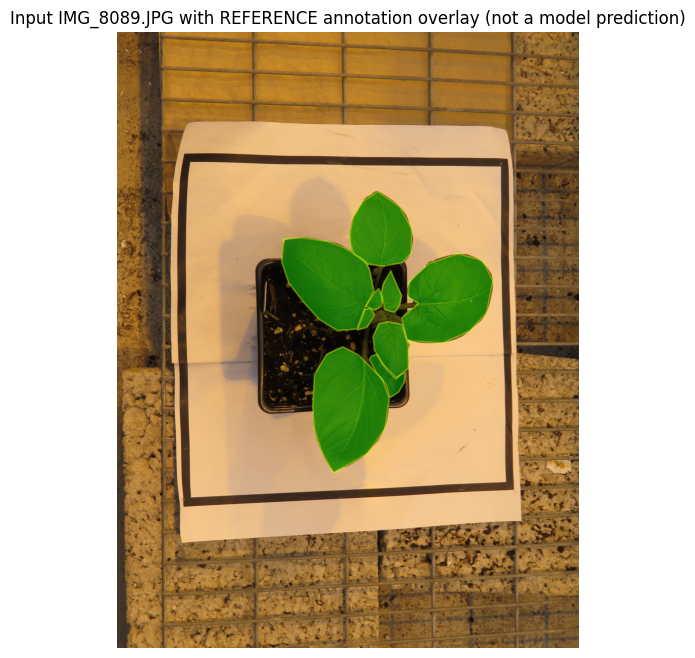

In [ ]:
import numpy as np, matplotlib.pyplot as plt

def collect_polygons(obj, polys):
    # Recursively find list-of-[x,y] number pairs; schema introspected in cell 5.
    if isinstance(obj, dict):
        for v in obj.values():
            collect_polygons(v, polys)
    elif isinstance(obj, list):
        if len(obj) >= 3 and all(isinstance(p, (list, tuple)) and len(p) >= 2
                                 and all(isinstance(c, (int, float)) for c in p[:2]) for p in obj):
            polys.append(np.array([[float(p[0]), float(p[1])] for p in obj]))
        else:
            for v in obj:
                collect_polygons(v, polys)

polys = []
collect_polygons(ann, polys)
# keep only polygons that plausibly lie inside the image
H, W = image_bgr.shape[:2]
polys = [p for p in polys if p[:, 0].max() <= W * 1.5 and p[:, 1].max() <= H * 1.5]
print(f"recognized {len(polys)} polygon-like annotation structures (image {W}x{H})")

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
for p in polys:
    ax.fill(p[:, 0], p[:, 1], facecolor="lime", edgecolor="yellow", alpha=0.35, linewidth=1.2)
ax.set_title("Input IMG_8089.JPG with REFERENCE annotation overlay (not a model prediction)")
ax.axis("off")
plt.show()
if not polys:
    print("No polygon-like structures recognized in the annotation JSON; overlay skipped (see cell 5 output).")

## 7. Authors' post-processing filters (copied verbatim)

Copy the authors' leaf-filter functions unchanged from `Leaf Only SAM.ipynb` @ `6abcf73`:
`checkcolour` (mean HSV hue 35–75, saturation > 35; widened to hue < 100 if nothing passes — the
grow-light fallback), `checkfullplant` (drop masks with IoU ≥ 0.9 against the union of all masks),
`checkshape` (largest-contour area / enclosing-circle area > 0.1), and the too-big mask removal.
The authors convert the **RGB** image to HSV with OpenCV's `COLOR_BGR2HSV`; this quirk is
intentionally preserved because their thresholds were tuned with it.

**日本語:** 著者のフィルタ関数群（ HSV 緑度・全株マスク除去・形状比・過大マスク除去）を
原著ノートブックから一字一句変更せずコピーします（GPL-3.0, 出典は冒頭）。

### 7a. `checkcolour` — greenness filter

Keep masks whose mean HSV hue is 35–75 with saturation > 35; if nothing passes, widen the hue
window to < 100 (the authors' grow-light fallback).

**日本語:** HSV の色相 35–75・彩度 35 超で「緑らしさ」を判定します。1つも通らなければ
植物育成灯を考慮して色相上限を 100 に広げます（著者の実装どおり）。

In [ ]:
def checkcolour(masks, hsv):
    colours = np.zeros((0,3))

    for i in range(len(masks)):
        color = hsv[masks[i]['segmentation']].mean(axis=(0))
        colours = np.append(colours,color[None,:], axis=0)

    idx_green = (colours[:,0]<75) & (colours[:,0]>35) & (colours[:,1]>35)
    if idx_green.sum()==0:
        # grow lights on adjust
        idx_green = (colours[:,0]<100) & (colours[:,0]>35) & (colours[:,1]>35)

    return(idx_green)

### 7b. `checkfullplant` and `checkshape` (with `iou` helper)

`checkfullplant` drops masks overlapping ≥ 0.9 IoU with the union of all masks (whole-plant
detections). `checkshape` computes the largest contour's area divided by its enclosing-circle area
and keeps masks with ratio > 0.1 (leaves are elongated; circles/pots are not).

**日本語:** 全株を覆うマスク（IoU≥0.9）を除去し、輪郭面積/外接円面積の比が 0.1 以下の
丸すぎるマスク（鉢など）を除去します。IoU ヘルパーも著者の原文どおりです。

In [ ]:
def checkfullplant(masks):
    mask_all = np.zeros(masks[0]['segmentation'].shape[:2])

    for mask in masks:
        mask_all +=mask['segmentation']*1

    iou_withall = []
    for mask in masks:
        iou_withall.append(iou(mask['segmentation'], mask_all>0))

    idx_notall = np.array(iou_withall)<0.9
    return idx_notall


def getbiggestcontour(contours):
    nopoints = [len(cnt) for cnt in contours]
    return(np.argmax(nopoints))


def checkshape(masks):
    cratio = []

    for i in range(len(masks)):
        test_mask = masks[i]['segmentation']

        if not test_mask.max():
            cratio.append(0)
        else:

            contours,hierarchy = cv2.findContours((test_mask*255).astype('uint8'), 1, 2)

            # multiple objects possibly detected. Find contour with most points on it and just use that as object
            cnt = contours[getbiggestcontour(contours)]
            M = cv2.moments(cnt)

            area = cv2.contourArea(cnt)
            perimeter = cv2.arcLength(cnt,True)

            (x,y),radius = cv2.minEnclosingCircle(cnt)

            carea = np.pi*radius**2

            cratio.append(area/carea)
    idx_shape = np.array(cratio)>0.1
    return(idx_shape)


def iou(gtmask, test_mask):
    intersection = np.logical_and(gtmask, test_mask)
    union = np.logical_or(gtmask, test_mask)
    iou_score = np.sum(intersection) / np.sum(union)
    return (iou_score)

### 7c. `istoobig` / `remove_toobig` — oversized near-duplicate removal

`istoobig` finds large masks that subsume ≥ 90% of smaller masks (when the union coverage
`mask_all` exceeds 1.5 there, i.e., real overlap exists); `remove_toobig` deletes a too-big mask
only when ≥ 90% of its area is covered by smaller kept masks. Verbatim author logic.

**日本語:** 小さいマスクをほぼ飲み込んでしまう過大マスクを検出し、
その領域の 9 割以上が他の保持マスクで覆われる場合にのみ削除します（著者の原文どおり）。

In [ ]:
def issubset(mask1, mask2):
    # is mask2 subpart of mask1
    intersection = np.logical_and(mask1, mask2)
    return(np.sum(intersection)/mask2.sum()>0.9)

def istoobig(masks):
    idx_toobig = []

    mask_all = np.zeros(masks[0]['segmentation'].shape[:2])

    for mask in masks:
        mask_all +=mask['segmentation']*1

    for idx in range(len(masks)):
        if idx in idx_toobig:
            continue
        for idx2 in range(len(masks)):
            if idx==idx2:
                continue
            if idx2 in idx_toobig:
                continue
            if issubset(masks[idx2]['segmentation'], masks[idx]['segmentation']):
                # check if actually got both big and small copy delete if do
                if mask_all[masks[idx2]['segmentation']].mean() > 1.5:

                    idx_toobig.append(idx2)

    idx_toobig.sort(reverse=True)
    return(idx_toobig)

def remove_toobig(masks, idx_toobig):
    masks_ntb = masks.copy()

    idx_del = []
    for idxbig in idx_toobig[1:]:
        maskbig = masks_ntb[idxbig]['segmentation'].copy()
        submasks = np.zeros(maskbig.shape)

        for idx in range(len(masks_ntb)):
            if idx==idxbig:
                continue
            if issubset(masks_ntb[idxbig]['segmentation'], masks_ntb[idx]['segmentation']):
                submasks +=masks_ntb[idx]['segmentation']

        if np.logical_and(maskbig, submasks>0).sum()/maskbig.sum()>0.9:
            # can safely remove maskbig
            idx_del.append(idxbig)
            del(masks_ntb[idxbig])

    return(masks_ntb)

## 8. Load SAM ViT-H on the GPU

Build the ViT-H model from the downloaded checkpoint and move it to CUDA, exactly as the authors do
(`sam_model_registry["vit_h"]`, `device="cuda"`). This cell also validates the checkpoint bytes by
actually loading them.

**日本語:** ダウンロードしたチェックポイントから ViT-H モデルを構築し、著者どおり CUDA に載せます。
ここでチェックポイントの完全性も検証されます。

In [ ]:
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator

assert torch.cuda.is_available(), (
    "No CUDA GPU: select a T4 GPU runtime (Runtime > Change runtime type). "
    "The authors' pipeline requires CUDA and CPU inference is impractically slow.")

sam_checkpoint = "sam_vit_h_4b8939.pth"
model_type = "vit_h"

device = "cuda"

sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(device=device)
print(f"SAM {model_type} loaded on {device}: "
      f"{sum(p.numel() for p in sam.parameters())/1e6:.0f}M parameters")

SAM vit_h loaded on cuda: 641M parameters


## 9. Run mask generation + leaf-only filtering on the sample

The authors' per-image loop, applied to the single sample: resize ×0.5, RGB + (quirky) HSV
conversion, `SamAutomaticMaskGenerator(points_per_side=32, pred_iou_thresh=0.88,
stability_score_thresh=0.95, crop_n_layers=1, crop_n_points_downscale_factor=2,
min_mask_region_area=200)`, then the verbatim filters. Stage counts are printed and the staged
`.npz` is saved exactly as the authors do (`<name>leafonly_allmasks.npz`).

**日本語:** 著者の画像ループを1枚のサンプルに適用します（0.5×縮小→AMG→逐次フィルタ）。
各段階のマスク数を表示し、著者と同じ形式で `.npz` 保存します。

In [ ]:
import time

folder = "sample/"     # trailing slash as the authors' code expects
folder_out = "out/"
os.makedirs(folder_out, exist_ok=True)
imname = "IMG_8089.JPG"

print(imname)
image = cv2.imread(folder + imname)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image = cv2.resize(image,None,fx=0.5,fy=0.5)   # downsize image to fit on gpu easier may not be needed
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)   # authors' original quirk: applied to the RGB image

# use crop_n_layers=1 to improve results on smallest leaves
mask_generator = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=32,
    pred_iou_thresh=0.88,
    stability_score_thresh=0.95,
    crop_n_layers=1,
    crop_n_points_downscale_factor=2,
    min_mask_region_area=200,
)

t0 = time.time()
masks = mask_generator.generate(image)
t_amg = time.time() - t0
print(f"SAM automatic mask generation: {len(masks)} masks in {t_amg:.1f}s on {device}")

idx_green = checkcolour(masks,hsv)
masks_g = [masks[idx] for idx, use in enumerate(idx_green) if use]

if len(masks_g) > 2:
    idx_notall = checkfullplant(masks_g)
    masks_na = [masks_g[idx] for idx, use in enumerate(idx_notall) if use]
else:
    masks_na = masks_g

idx_shape = checkshape(masks_na)
masks_s = [masks_na[idx] for idx, use in enumerate(idx_shape) if use]

idx_toobig = istoobig(masks_s)
masks_ntb = remove_toobig(masks_s, idx_toobig)

print(f"stage counts -> all SAM masks: {len(masks)} | green (checkcolour): {len(masks_g)} | "
      f"not full plant: {len(masks_na)} | shape pass: {len(masks_s)} | after too-big removal: {len(masks_ntb)}")

np.savez(folder_out + imname.replace('.JPG','leafonly_allmasks.npz'),
          masks, masks_g, masks_na, masks_s, masks_ntb)
print("saved staged results to", folder_out + imname.replace('.JPG','leafonly_allmasks.npz'))

IMG_8089.JPG


SAM automatic mask generation: 77 masks in 32.0s on cuda


stage counts -> all SAM masks: 77 | green (checkcolour): 17 | not full plant: 16 | shape pass: 15 | after too-big removal: 14


saved staged results to out/IMG_8089leafonly_allmasks.npz


## 10. Visualize: all SAM masks vs Leaf-Only output

Overlay (top) every raw SAM mask with random colours and (bottom) the final leaf-only masks
(`masks_ntb`) after the authors' filters. This is the paper's zero-shot pipeline output for the
one sample — a qualitative demonstration, **not** a measurement of the paper's reported recall or
precision.

**日本語:** 生の SAM マスク（上）と、著者フィルタ後の葉のみマスク（下）を重ねて表示します。
これは定性的な1事例のデモンストレーションであり、論文の recall/precision の測定ではありません。

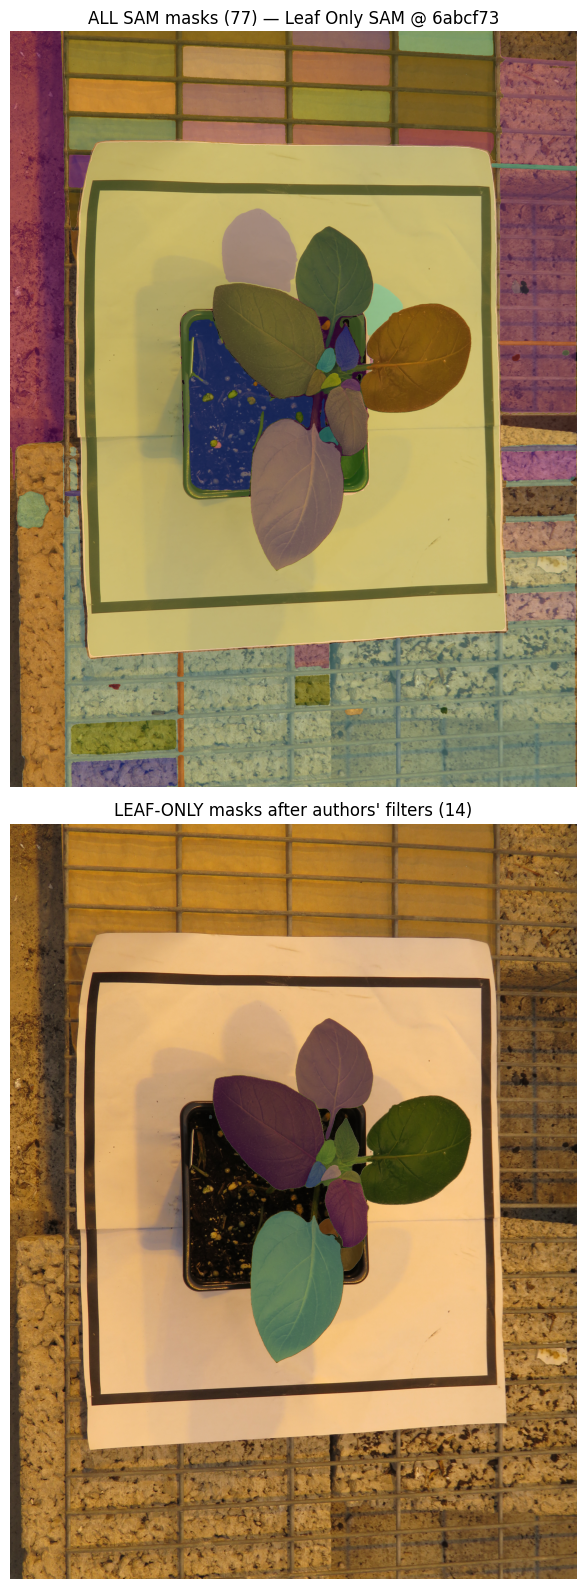

In [ ]:
def show_anns(ax, anns, title):
    if len(anns) == 0:
        ax.set_title(title + " (none)")
        return
    sorted_anns = sorted(anns, key=(lambda x: x['area']), reverse=True)
    img = np.ones((sorted_anns[0]['segmentation'].shape[0],
                   sorted_anns[0]['segmentation'].shape[1], 4))
    img[:, :, 3] = 0
    rng = np.random.RandomState(3)  # fixed seed: reproducible colours, colours are cosmetic only
    for ann in sorted_anns:
        m = ann['segmentation']
        color_mask = np.concatenate([rng.random(3), [0.35]])
        img[m] = color_mask
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

fig, axes = plt.subplots(2, 1, figsize=(10, 16))
axes[0].imshow(image)
show_anns(axes[0], masks, f"ALL SAM masks ({len(masks)}) — Leaf Only SAM @ 6abcf73")
axes[1].imshow(image)
show_anns(axes[1], masks_ntb, f"LEAF-ONLY masks after authors' filters ({len(masks_ntb)})")
plt.tight_layout()
plt.savefig("out/leaf_only_sam_result.png", dpi=120, bbox_inches="tight")
plt.show()

## 11. Results table and CSV export

Summarize the zero-shot pipeline stages for this sample and export them as CSV (within Colab),
including the reference annotation count recognized in cell 6 for context.

**日本語:** 各段階のマスク数を表にまとめ、Colab 内に CSV として保存します。

In [ ]:
import pandas as pd

summary = pd.DataFrame([
    {"stage": "all_sam_masks", "count": len(masks)},
    {"stage": "after_checkcolour_green", "count": len(masks_g)},
    {"stage": "after_checkfullplant", "count": len(masks_na)},
    {"stage": "after_checkshape", "count": len(masks_s)},
    {"stage": "after_remove_toobig_leafonly", "count": len(masks_ntb)},
    {"stage": "reference_annotation_polygons", "count": len(polys)},
])
print(summary.to_string(index=False))
summary.to_csv("out/leaf_only_sam_summary.csv", index=False)
print("saved out/leaf_only_sam_summary.csv")
print(f"timing: SAM mask generation {t_amg:.1f}s on {device} (measured this run)")

                        stage  count
                all_sam_masks     77
      after_checkcolour_green     17
         after_checkfullplant     16
             after_checkshape     15
 after_remove_toobig_leafonly     14
reference_annotation_polygons      9
saved out/leaf_only_sam_summary.csv
timing: SAM mask generation 32.0s on cuda (measured this run)


## 12. Interpretation and limitations

**What was executed:** the authors' zero-shot Leaf Only SAM pipeline, copied verbatim from their
released notebook (commit `6abcf73`), ran end-to-end on one annotated potato image from their
Zenodo dataset (CC-BY), on a Colab GPU (measured hardware printed in cells 1/9/11).

**Limitations (read before drawing conclusions):**
- One image demonstrates the *procedure*, not the paper's dataset-level recall/precision; those
  benchmarks (and the Mask R-CNN comparison) are out of scope because the fine-tuning/evaluation
  code was never released and the published journal text is paywalled.
- The authors' filter thresholds are heuristic and image-conditioned (e.g., the hue-window widening
  for grow lights); a different sample may filter differently.
- The reference `.json` overlay shows human annotations for visual context; no IoU against it is
  computed here because the paper's evaluation protocol (splits, matching rule) is not available
  from released materials.

**日本語:** 本ノートブックは著者リリースのコードをそのまま実行した1事例の再現です。
データセット全体の精度再現や Mask R-CNN との比較（未公開コード）は含みません。

**References:** Leaf Only SAM notebook, Dom3442/leafonlysam @ `6abcf73` (GPL-3.0);
Zenodo record 7938231 (CC-BY); segment-anything @ `dca509fe`; DOI 10.1016/j.atech.2024.100515;
arXiv:2305.09418. Provenance and checksums are recorded in the report and in cells above.